# Dissecting SAM 3

The SAM3 notebook shows how to *use* Meta's Segment Anything 3: give it an image and a concept ("goat") and it returns
a mask for every instance. This notebook takes the image model (`Sam3Model`) apart with PyTorch introspection —
printing modules, counting parameters, and recording the shape of every tensor that flows through it — to see how a
prompt and an image turn into 200 candidate objects with boxes, scores and masks.

The model combines architectures you have seen in this course: a **Vision Transformer** for the image, a **CLIP text
encoder** for the prompt, a **feature pyramid** of convolutions, a **DETR-style detector** (a Transformer encoder and
decoder with learned object queries), and a **mask head** that turns each object query into a mask with a dot product.
All of it is built from the same basic blocks: **convolutions, layer and group norms, attention, dense layers, and
embeddings**.

Like the SAM3 notebook, it needs a GPU instance (`ml.g4dn.4xlarge`).

In [1]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import s3fs
import torch
from PIL import Image
from transformers import Sam3Model, Sam3Processor
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
warnings.filterwarnings("ignore", category=FutureWarning)  # deprecations inside the libraries
# The figures are mostly photos: JPEG at retina resolution keeps the notebook small.
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 144, 'pil_kwargs': {'quality': 85}}

device = "cuda" if torch.cuda.is_available() else "cpu"

# The weights, as in the SAM3 notebook: downloaded once from the course bucket to sam3_model/ next to this notebook.
MODEL_S3 = "danylo-ucla/models/facebook/sam3"
MODEL_DIR = Path("sam3_model")
if not (MODEL_DIR / "model.safetensors").exists():
    s3fs.S3FileSystem().get(f"{MODEL_S3}/", str(MODEL_DIR), recursive=True)

model = Sam3Model.from_pretrained(MODEL_DIR).to(device).eval()
processor = Sam3Processor.from_pretrained(MODEL_DIR)
config = model.config

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

## 1. The module tree

`print(model)` shows the nested `torch.nn.Module`s; PyTorch collapses identical repeated layers
(e.g. `(0-31): 32 x Sam3ViTLayer`). `Dropout` layers do nothing in `eval()` mode.

In [2]:
print(model)

Sam3Model(
  (vision_encoder): Sam3VisionModel(
    (backbone): Sam3ViTModel(
      (embeddings): Sam3ViTEmbeddings(
        (patch_embeddings): Sam3ViTPatchEmbeddings(
          (projection): Conv2d(3, 1024, kernel_size=(14, 14), stride=(14, 14), bias=False)
        )
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (layer_norm): LayerNorm((1024,), eps=1e-06, elementwise_affine=True, bias=True)
      (layers): ModuleList(
        (0-31): 32 x Sam3ViTLayer(
          (layer_norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True, bias=True)
          (rotary_emb): Sam3ViTRotaryEmbedding()
          (attention): Sam3ViTRoPEAttention(
            (q_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (k_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (v_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (o_proj): Linear(in_features=1024, out_features=1024, bias=True)
          )
          (layer_no

The model has eight top-level parts:

1. `vision_encoder` — a ViT (`backbone`) that turns the image into a 72 × 72 grid of 1024-d vectors, and a feature pyramid (`neck`) that resamples it to several resolutions with 256 channels;
2. `text_encoder` — the text half of a CLIP model, one 1024-d vector per prompt token; `text_projection` maps them to 256;
3. `geometry_encoder` — turns example boxes (if any) into extra prompt tokens;
4. `detr_encoder` — a Transformer that mixes the prompt into the image tokens;
5. `detr_decoder` — a Transformer with 200 learned *object queries* that each look for one object, plus a *presence* token;
6. `dot_product_scoring` — scores each query against the prompt;
7. `mask_decoder` — turns each query into a mask.

The configuration values that determine the architecture:

In [3]:
backbone, text = config.vision_config.backbone_config, config.text_config
{
    "image size": backbone.image_size, "patch size": backbone.patch_size, "ViT layers": backbone.num_hidden_layers,
    "ViT width": backbone.hidden_size, "ViT heads": backbone.num_attention_heads, "ViT MLP": backbone.intermediate_size,
    "attention window (patches)": backbone.window_size, "global attention layers": backbone.global_attn_indexes,
    "FPN scale factors": config.vision_config.scale_factors, "FPN channels": config.vision_config.fpn_hidden_size,
    "text layers": text.num_hidden_layers, "text width": text.hidden_size, "text tokens": text.max_position_embeddings,
    "DETR encoder layers": config.detr_encoder_config.num_layers, "DETR decoder layers": config.detr_decoder_config.num_layers,
    "object queries": config.detr_decoder_config.num_queries, "DETR width": config.detr_decoder_config.hidden_size,
}

{'image size': 1008,
 'patch size': 14,
 'ViT layers': 32,
 'ViT width': 1024,
 'ViT heads': 16,
 'ViT MLP': 4736,
 'attention window (patches)': 24,
 'global attention layers': [7, 15, 23, 31],
 'FPN scale factors': [4.0, 2.0, 1.0, 0.5],
 'FPN channels': 256,
 'text layers': 24,
 'text width': 1024,
 'text tokens': 32,
 'DETR encoder layers': 6,
 'DETR decoder layers': 6,
 'object queries': 200,
 'DETR width': 256}

### Where the parameters are

In [4]:
def n_params(module: torch.nn.Module) -> int:
    return sum(p.numel() for p in module.parameters())


stages = {
    "vision_encoder.backbone (ViT)": model.vision_encoder.backbone,
    "vision_encoder.neck (FPN)": model.vision_encoder.neck,
    "text_encoder (CLIP)": model.text_encoder,
    "text_projection": model.text_projection,
    "geometry_encoder": model.geometry_encoder,
    "detr_encoder": model.detr_encoder,
    "detr_decoder": model.detr_decoder,
    "dot_product_scoring": model.dot_product_scoring,
    "mask_decoder": model.mask_decoder,
}
table = pd.DataFrame({"parameters": {name: n_params(m) for name, m in stages.items()}})
table.loc["total"] = n_params(model)
table["share"] = (table["parameters"] / n_params(model)).map("{:.1%}".format)
table

,parameters,share
vision_encoder.backbone (ViT),446236672,53.1%
vision_encoder.neck (FPN),7802112,0.9%
text_encoder (CLIP),353462272,42.1%
text_projection,262400,0.0%
geometry_encoder,8083456,1.0%
detr_encoder,9472512,1.1%
detr_decoder,11575093,1.4%
dot_product_scoring,1182976,0.1%
mask_decoder,2298881,0.3%
total,840376374,100.0%


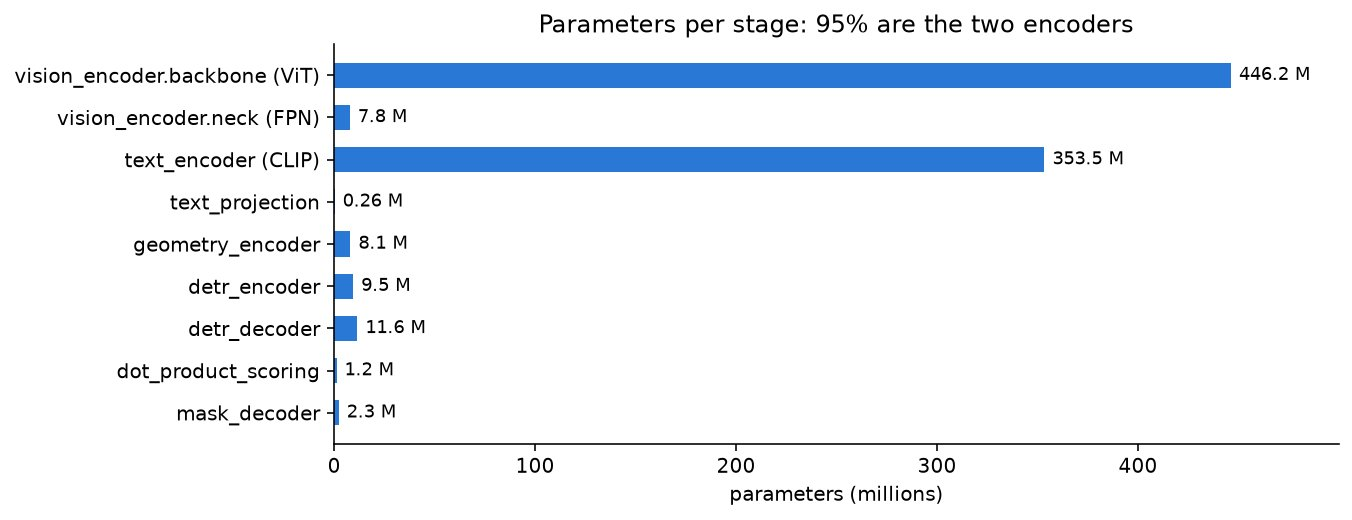

In [5]:
parts = table.drop(index="total")["parameters"][::-1] / 1e6
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(parts.index, parts.values, color=COLORS[0], height=0.6)
for y, v in enumerate(parts.values):
    ax.text(v + 4, y, f"{v:.1f} M" if v >= 1 else f"{v:.2f} M", va="center", fontsize=9)
ax.set(xlabel="parameters (millions)", title="Parameters per stage: 95% are the two encoders",
       xlim=(0, parts.max() * 1.12))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

And grouped by the type of basic block (summed over all occurrences):

In [6]:
by_type = {}
for name, module in model.named_modules():
    own = sum(p.numel() for p in module.parameters(recurse=False))
    if own:
        kind = "Embedding" if isinstance(module, torch.nn.Embedding) else type(module).__name__
        count, total = by_type.get(kind, (0, 0))
        by_type[kind] = (count + 1, total + own)

pd.DataFrame(by_type, index=["modules", "parameters"]).T.sort_values("parameters", ascending=False)

,modules,parameters
Linear,538,775390229
Embedding,7,50679584
Conv2d,15,8732161
ConvTranspose2d,3,4719872
Sam3ViTEmbeddings,1,589824
LayerNorm,172,263168
GroupNorm,3,1536


As in the other Transformers, almost all parameters are in `Linear` layers. The detector and the mask head —
the parts that are specific to segmentation — are small: 33 M of the 840 M parameters. Most of the work of
SAM 3 is in *understanding* the image and the prompt.

## 2. Tracing shapes with forward hooks

We register a *forward hook* on every basic block, run one image with a text prompt **and** an example box (so
that every part of the model runs), and record the input and output shape of each block.

In [7]:
def load_coco(image_id: int) -> Image.Image:
    url = f"https://s3.us-east-1.amazonaws.com/images.cocodataset.org/val2017/{image_id:012d}.jpg"
    return Image.open(requests.get(url, stream=True).raw).convert("RGB")


goats = load_coco(181666)
example_box = [343, 280, 428, 391]  # one goat, in pixels
inputs = processor(images=goats, text="goat", input_boxes=[[example_box]], input_boxes_labels=[[1]],
                   return_tensors="pt").to(device)
print("image:", goats.size, {name: tuple(value.shape) for name, value in inputs.items()})

image: (640, 425) {'pixel_values': (1, 3, 1008, 1008), 'original_sizes': (1, 2), 'input_ids': (1, 32), 'attention_mask': (1, 32), 'input_boxes': (1, 1, 4), 'input_boxes_labels': (1, 1)}


In [8]:
BASIC = (torch.nn.Conv2d, torch.nn.ConvTranspose2d, torch.nn.MaxPool2d, torch.nn.LayerNorm, torch.nn.GroupNorm,
         torch.nn.Linear, torch.nn.Embedding, torch.nn.GELU, torch.nn.ReLU)
ATTENTION = ("Sam3ViTRoPEAttention", "Sam3Attention", "CLIPAttention")


def first_tensor(x):
    while isinstance(x, (tuple, list)):
        x = x[0]
    return x


records = []


def make_hook(name):
    def hook(module, args, kwargs, output):
        x = args[0] if args else next(iter(kwargs.values()))
        attention = type(module).__name__ in ATTENTION
        records.append({
            "module": name,
            "type": type(module).__name__,
            "input": tuple(first_tensor(x).shape),
            "output": tuple(first_tensor(output).shape),
            "parameters": 0 if attention else n_params(module),
        })
    return hook


handles = [m.register_forward_hook(make_hook(n), with_kwargs=True) for n, m in model.named_modules()
           if isinstance(m, BASIC) or type(m).__name__ in ("GELUActivation",) + ATTENTION]
with torch.no_grad():
    outputs = model(**inputs)
for h in handles:
    h.remove()

trace = pd.DataFrame(records)
print(len(trace), "calls of", trace["module"].nunique(), "modules")

979 calls of 899 modules


Repeated layers are grouped by the sequence of shapes they produce. The 32 ViT layers come in **two** kinds
(windowed and global attention, see section 3); the layers of each other stack are all identical. Each group is
shown once, labelled with the layer numbers it stands for.

In [9]:
parts = trace["module"].str.extract(r"^(?P<stack>.*\.layers)\.(?P<layer>\d+)\.(?P<rest>.*)$")
trace = trace.join(parts)
signatures = (trace.dropna(subset="layer")
              .groupby(["stack", "layer"], sort=False)
              .apply(lambda g: tuple(map(tuple, g[["rest", "type", "input", "output"]].values)), include_groups=False))


def ranges(numbers):
    numbers, out = sorted(numbers), []
    for n in numbers:
        if out and n == out[-1][1] + 1:
            out[-1][1] = n
        else:
            out.append([n, n])
    return ",".join(str(a) if a == b else f"{a}-{b}" for a, b in out)


label = {}
for stack, group in signatures.groupby(level="stack", sort=False):
    for signature, layers in group.groupby(group, sort=False):
        numbers = [int(layer) for _, layer in layers.index]
        for layer in layers.index.get_level_values("layer"):
            label[(stack, layer)] = (f"{{{ranges(numbers)}}}", str(min(numbers)))

keep = trace["layer"].isna() | np.array([label.get((s, l), (None, None))[1] == l
                                         for s, l in zip(trace["stack"], trace["layer"])])
collapsed = trace[keep].copy()
collapsed["module"] = [m if pd.isna(s) else f"{s}.{label[(s, l)][0]}.{r}"
                       for m, s, l, r in zip(collapsed["module"], collapsed["stack"], collapsed["layer"], collapsed["rest"])]
collapsed = collapsed.drop(columns=["stack", "layer", "rest"]).drop_duplicates(subset=["module", "input", "output"])

with pd.option_context("display.max_rows", 200, "display.max_colwidth", 70):
    display(collapsed.reset_index(drop=True))

,module,type,input,output,parameters
0,vision_encoder.backbone.embeddings.patch_embeddings.projection,Conv2d,"(1, 3, 1008, 1008)","(1, 1024, 72, 72)",602112
1,vision_encoder.backbone.layer_norm,LayerNorm,"(1, 72, 72, 1024)","(1, 72, 72, 1024)",2048
2,"vision_encoder.backbone.layers.{0-6,8-14,16-22,24-30}.layer_norm1",LayerNorm,"(1, 72, 72, 1024)","(1, 72, 72, 1024)",2048
3,"vision_encoder.backbone.layers.{0-6,8-14,16-22,24-30}.attention.q_...",Linear,"(9, 24, 24, 1024)","(9, 24, 24, 1024)",1049600
4,"vision_encoder.backbone.layers.{0-6,8-14,16-22,24-30}.attention.k_...",Linear,"(9, 24, 24, 1024)","(9, 24, 24, 1024)",1049600
5,"vision_encoder.backbone.layers.{0-6,8-14,16-22,24-30}.attention.v_...",Linear,"(9, 24, 24, 1024)","(9, 24, 24, 1024)",1049600
6,"vision_encoder.backbone.layers.{0-6,8-14,16-22,24-30}.attention.o_...",Linear,"(9, 24, 24, 1024)","(9, 24, 24, 1024)",1049600
7,"vision_encoder.backbone.layers.{0-6,8-14,16-22,24-30}.attention",Sam3ViTRoPEAttention,"(9, 24, 24, 1024)","(9, 24, 24, 1024)",0
8,"vision_encoder.backbone.layers.{0-6,8-14,16-22,24-30}.layer_norm2",LayerNorm,"(1, 72, 72, 1024)","(1, 72, 72, 1024)",2048
9,"vision_encoder.backbone.layers.{0-6,8-14,16-22,24-30}.mlp.fc1",Linear,"(1, 72, 72, 1024)","(1, 72, 72, 4736)",4854400


Reading the table top to bottom is reading the forward pass. Some things it shows:

- In windowed ViT layers, the attention works on `(9, 24, 24, 1024)`: the 72 × 72 grid is cut into 9 windows of
  24 × 24 patches that are processed as a batch of 9. The 4 global layers attend over the whole `(1, 72, 72, 1024)` grid.
- The prompt has **34 tokens**: 32 text tokens (padded) + the example box + a CLS token from the geometry encoder.
  Every cross-attention to the prompt has keys and values of length 34.
- The DETR decoder works on **201** vectors: 200 object queries + the presence token.
- The masks come from an `einsum` (not a module, so not in the table): each of the 200 query embeddings
  `(200, 256)` is multiplied with the pixel embedding `(256, 288, 288)`.

Hooks also reveal computation that is done but not used, and weights that are never used. (Some `Embedding`s
never run either, but for a different reason: the model reads their `.weight` directly, e.g. the 200 learned
queries, so no forward hook fires.)

In [10]:
called = set(trace["module"])
not_called = [name for name, m in model.named_modules()
              if name and name not in called and isinstance(m, BASIC) and n_params(m) > 0]
print("Embeddings read through .weight:", [n for n in not_called if isinstance(model.get_submodule(n), torch.nn.Embedding)])
print("modules with parameters that never ran:", [n for n in not_called
                                                  if not isinstance(model.get_submodule(n), torch.nn.Embedding)])
print("CLIP's own projection runs, but SAM 3 uses its own text_projection instead:",
      trace.query("module == 'text_encoder.text_projection'")[["input", "output"]].values.tolist())
print("the FPN computes 4 levels; Sam3Model uses the first 3 (the 36 × 36 level is for the video tracker):",
      [tuple(level.shape[-2:]) for level in model.vision_encoder(inputs["pixel_values"]).fpn_hidden_states])

Embeddings read through .weight: ['geometry_encoder.cls_embed', 'detr_decoder.query_embed', 'detr_decoder.reference_points', 'detr_decoder.presence_token']
modules with parameters that never ran: ['mask_decoder.pixel_decoder.conv_layers.2', 'mask_decoder.pixel_decoder.norms.2']
CLIP's own projection runs, but SAM 3 uses its own text_projection instead: [[(1, 1024), (1, 512)]]


the FPN computes 4 levels; Sam3Model uses the first 3 (the 36 × 36 level is for the video tracker): [(288, 288), (144, 144), (72, 72), (36, 36)]


### The architecture as a diagram

The same information as a picture, one box per stage, colored by what it works on. Arrows marked *k, v* are
cross-attentions: the stage the arrow points to attends to (takes keys and values from) the source.

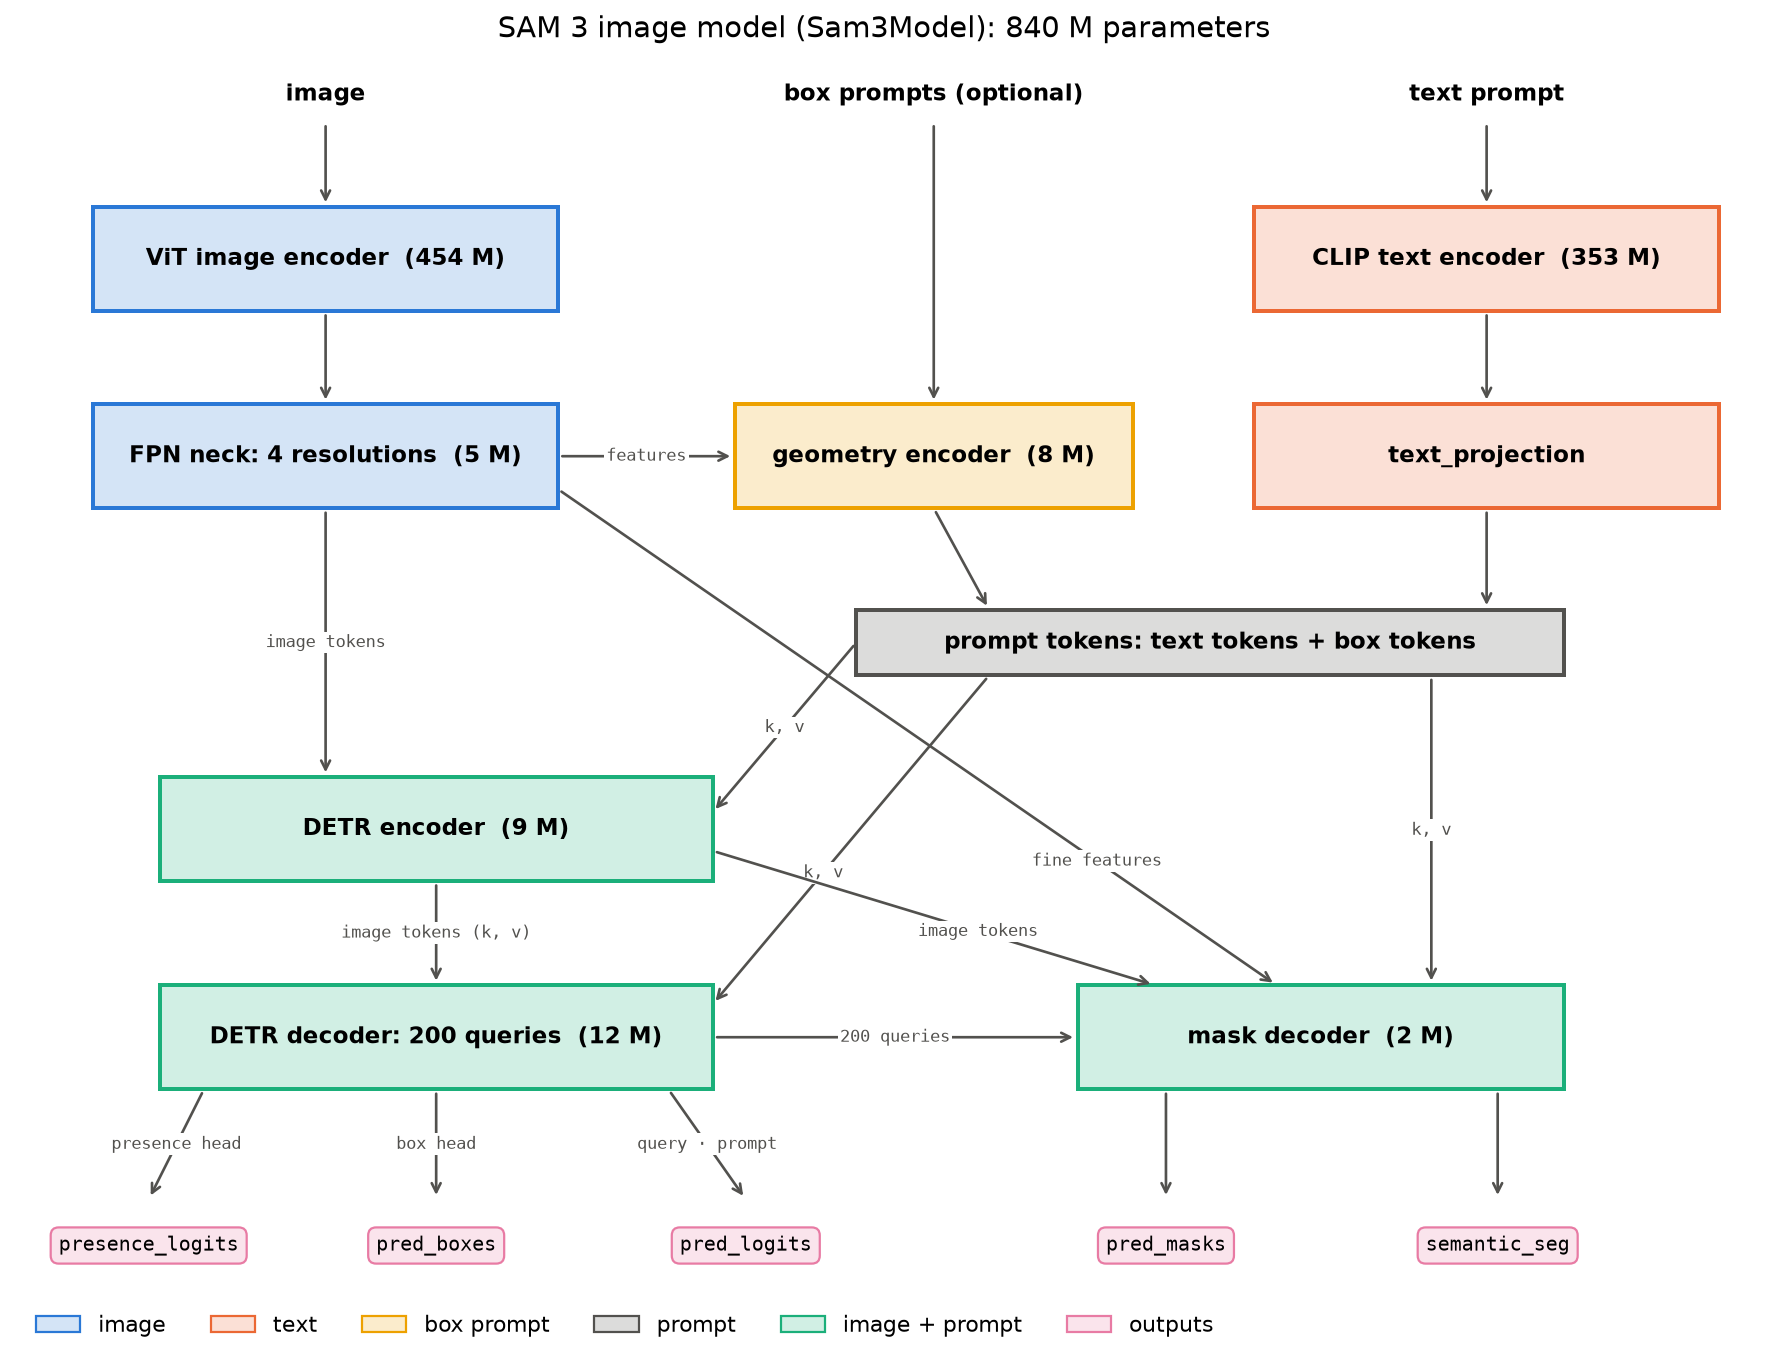

## 3. The image encoder

### Patches and windows

The processor resizes every image to 1008 × 1008 pixels. A `Conv2d` with a 14 × 14 kernel and stride 14 cuts it into
$72 \times 72 = 5184$ patches and embeds each one as a 1024-d vector. Positions are encoded twice: a learned
24 × 24 position embedding (the ViT's pre-training size, tiled 3 × 3) is added to the patches (the 589 824 parameters
of `Sam3ViTEmbeddings` above), and inside every attention layer **RoPE** (rotary position embeddings) rotates the
query and key vectors by angles that depend on each patch's row and column.

Self-attention over all 5184 patches costs $5184^2 \approx 27$ M attention weights per head. To save compute, 28 of the
32 layers attend only **within windows** of 24 × 24 patches (336 × 336 pixels, the image size the ViT was pre-trained
on), $9 \cdot 576^2 \approx 3$ M weights per head. The 4 global layers (8, 16, 24, 32 counting from 1) let information
flow between windows.

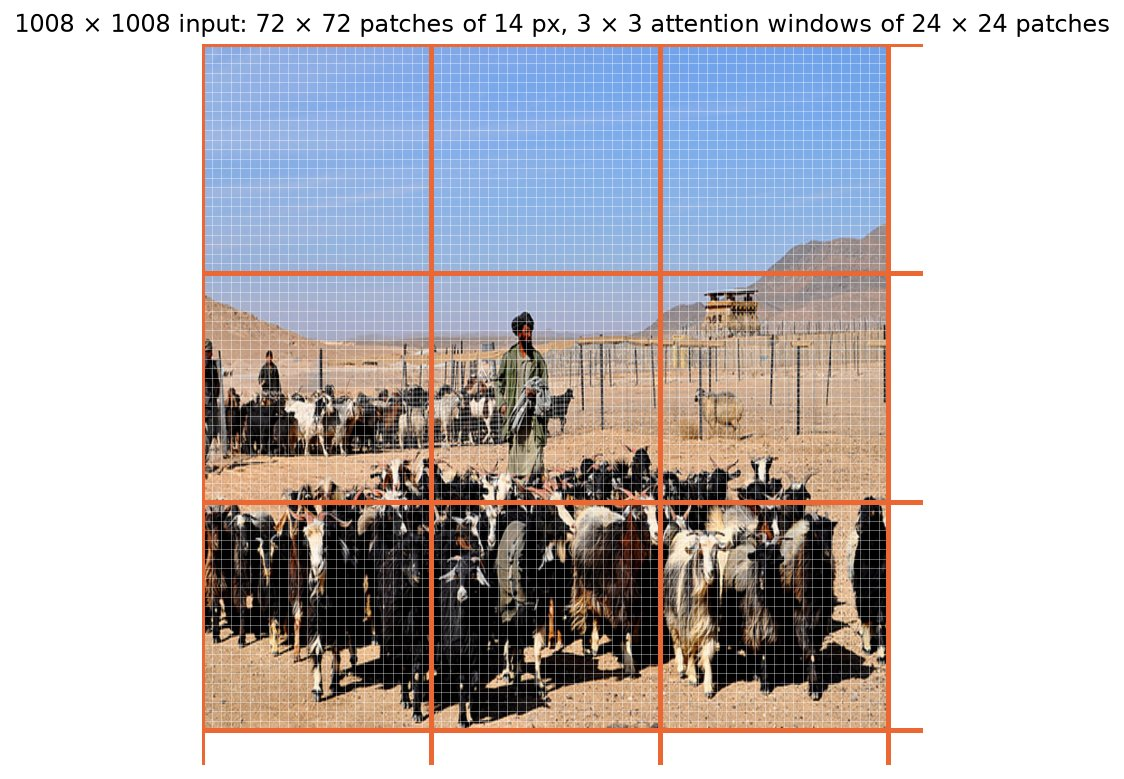

In [11]:
resized = goats.resize((1008, 1008))
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(resized)
for k in range(0, 1009, 14):  # patches
    ax.axhline(k, color="white", lw=0.3, alpha=0.6)
    ax.axvline(k, color="white", lw=0.3, alpha=0.6)
for k in range(0, 1009, 336):  # windows
    ax.axhline(k, color=COLORS[1], lw=2.5)
    ax.axvline(k, color=COLORS[1], lw=2.5)
ax.set(title="1008 × 1008 input: 72 × 72 patches of 14 px, 3 × 3 attention windows of 24 × 24 patches")
ax.axis("off")
plt.show()

### The feature pyramid

Detection and segmentation need fine detail (mask edges) and large context (whole objects) at once. The `neck`
resamples the ViT's single 72 × 72 output to four resolutions — with transposed convolutions (×4, ×2), unchanged, and
max pooling (½) — and projects each to 256 channels.

To look at 256 channels at once, we project them onto their 3 main directions (PCA) and show those as red, green, blue:
pixels with similar features get similar colors.

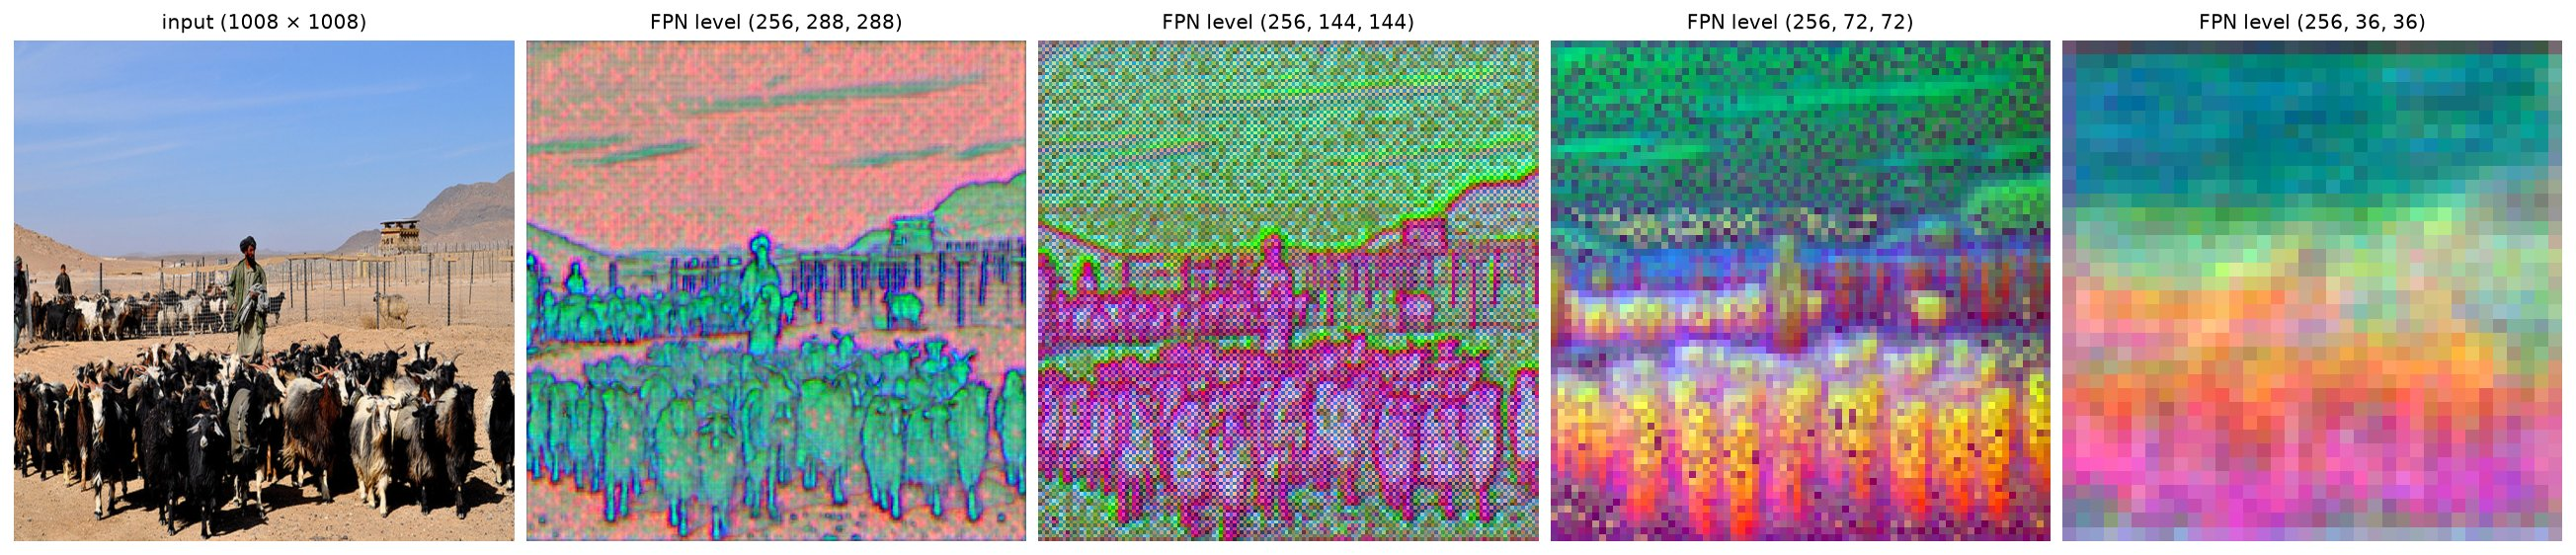

In [12]:
with torch.no_grad():
    vision = model.vision_encoder(inputs["pixel_values"])


def pca_rgb(features):
    """(C, H, W) -> (H, W, 3): the first 3 principal components, scaled to [0, 1]."""
    c, h, w = features.shape
    x = features.reshape(c, -1).T.float()
    x = x - x.mean(dim=0)
    _, _, v = torch.pca_lowrank(x, q=3, center=False)
    rgb = (x @ v[:, :3]).reshape(h, w, 3)
    low, high = rgb.quantile(0.01), rgb.quantile(0.99)
    return ((rgb - low) / (high - low)).clamp(0, 1).cpu().numpy()


fig, axes = plt.subplots(1, 5, figsize=(18, 3.8), layout="constrained")
axes[0].imshow(resized)
axes[0].set_title("input (1008 × 1008)", fontsize=10)
for ax, level in zip(axes[1:], vision.fpn_hidden_states):
    ax.imshow(pca_rgb(level[0]))
    ax.set_title(f"FPN level {tuple(level.shape[1:])}", fontsize=10)
for ax in axes:
    ax.axis("off")
plt.show()

Even without any prompt, the features already separate goats, people, ground, fence and sky — this is what the
encoder learned from its training on 4 million images with 52 million masks.

## 4. The prompt: text tokens and box tokens

The text prompt is tokenized by CLIP's tokenizer and padded to 32 tokens; the `attention_mask` marks the real ones.
The CLIP text encoder (24 Transformer layers) gives one 1024-d vector per token, and `text_projection` maps each to
the detector's 256 dimensions.

In [13]:
tokens = processor.tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
print("text tokens:", [t for t, m in zip(tokens, inputs["attention_mask"][0]) if m],
      f"+ {int((inputs['attention_mask'][0] == 0).sum())} padding")
with torch.no_grad():
    text_features = model.get_text_features(input_ids=inputs["input_ids"], attention_mask=inputs["attention_mask"])
print("CLIP output:", tuple(text_features.last_hidden_state.shape), "-> projected:", tuple(text_features.pooler_output.shape))

text tokens: ['<|startoftext|>', 'goat</w>', '<|endoftext|>'] + 29 padding
CLIP output: (1, 32, 1024) -> projected: (1, 32, 256)


Each example box becomes one more prompt token. The geometry encoder combines three descriptions of the box —
its coordinates (`Linear` on $c_x, c_y, w, h$), a sine encoding of its position, and the image features inside it
(*RoI pooling*: the 72 × 72 features under the box are resampled to 7 × 7 and reduced by a 7 × 7 `Conv2d`) — plus an
embedding of its label (positive or negative). A learned CLS token is added, and 3 Transformer layers let the box
tokens attend to each other and to the image.

In [14]:
with torch.no_grad():
    geometry = model.geometry_encoder(
        box_embeddings=inputs["input_boxes"], box_mask=torch.ones(1, 1, dtype=torch.bool, device=device),
        box_labels=inputs["input_boxes_labels"], img_feats=vision.fpn_hidden_states[:-1],
        img_pos_embeds=vision.fpn_position_encoding[:-1])
print("box (cx, cy, w, h as fractions of the image):", inputs["input_boxes"][0].tolist())
print("box tokens:", tuple(geometry.last_hidden_state.shape), "(the box + CLS)")
print("prompt tokens:", text_features.pooler_output.shape[1], "+", geometry.last_hidden_state.shape[1],
      "=", text_features.pooler_output.shape[1] + geometry.last_hidden_state.shape[1])

box (cx, cy, w, h as fractions of the image): [[0.602343738079071, 0.7894117832183838, 0.1328125, 0.2611764669418335]]
box tokens: (1, 2, 256) (the box + CLS)
prompt tokens: 32 + 2 = 34


## 5. The detector: DETR encoder and decoder

The detector follows **DETR** (*DEtection TRansformer*, Carion et al. 2020): instead of sliding a classifier over the
image, a fixed number of learned **object queries** each look for one object, and a set of boxes comes out directly.

**Encoder** (6 pre-norm layers): the 5184 image tokens (the 72 × 72 FPN level, with a sine position encoding) attend to
each other and to the prompt tokens:

$$h = x + \mathrm{SelfAttn}(\mathrm{LN}(x)) \qquad g = h + \mathrm{CrossAttn}(\mathrm{LN}(h), \text{prompt}) \qquad y = g + \mathrm{MLP}(\mathrm{LN}(g))$$

After the encoder, the image tokens "know" what is being looked for.

**Decoder** (6 post-norm layers): 200 learned query vectors, each with a learned **reference box**, plus one
**presence token**. In each layer the queries attend to each other (so that two queries don't take the same object),
to the prompt tokens, and to the image tokens. The image cross-attention has a *box-position bias*: each query
attends mostly to the image tokens near its current box. After each layer, a box head (3-layer MLP) predicts a
correction to every box:

$$b^{(\ell+1)} = \sigma\big(\sigma^{-1}(b^{(\ell)}) + \mathrm{MLP}(q^{(\ell)})\big)$$

### The 200 reference boxes

Before seeing any image, each query starts at its own learned box. Perhaps surprisingly, the 200 starting boxes are
all large boxes around the center of the image: the queries do not divide the image into regions in advance. Which
object a query ends up on is decided by the image and the prompt, through the decoder's attention.

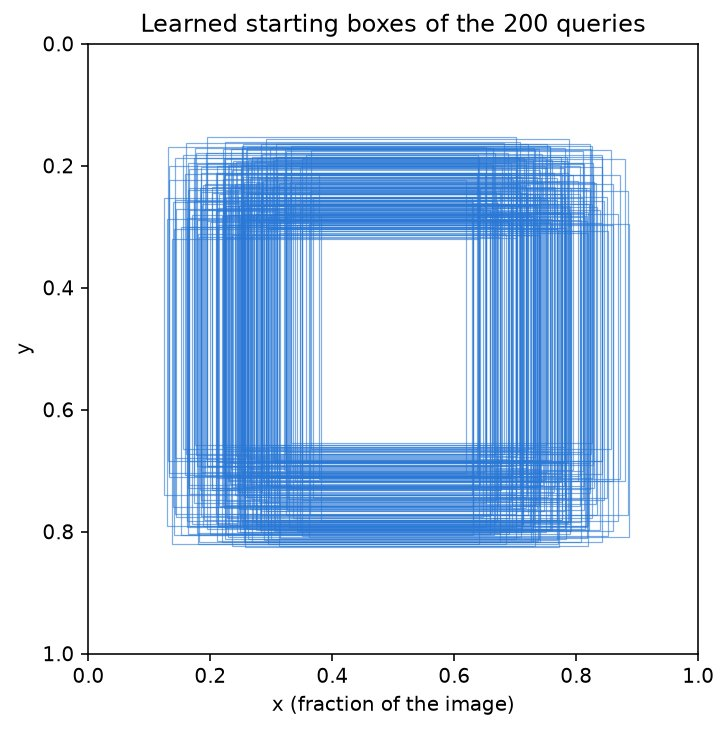

In [15]:
start_boxes = model.detr_decoder.reference_points.weight.sigmoid().detach().cpu()  # (200, 4): cx, cy, w, h in [0, 1]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
for cx, cy, w, h in start_boxes:
    ax.add_patch(plt.Rectangle((cx - w / 2, cy - h / 2), w, h, fill=False, edgecolor=COLORS[0], lw=0.6, alpha=0.6))
ax.set(xlim=(0, 1), ylim=(1, 0), aspect="equal", title="Learned starting boxes of the 200 queries",
       xlabel="x (fraction of the image)", ylabel="y")
plt.show()

### Box refinement, layer by layer

`decoder_reference_boxes` holds each query's box at the input of each of the 6 decoder layers; `pred_boxes` is the
box after the last one. For the 5 best-scoring queries, the box moves from its learned start to the object in a few
layers (light → dark):

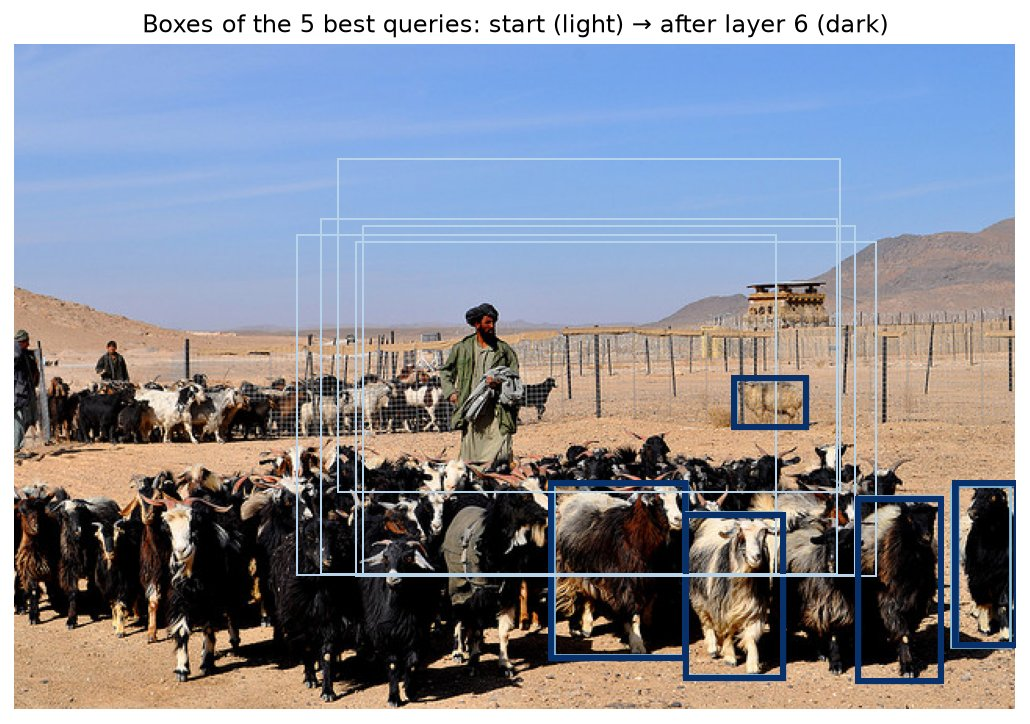

In [16]:
scores = (outputs.pred_logits.sigmoid() * outputs.presence_logits.sigmoid())[0]
best = scores.argsort(descending=True)[:5].cpu()
steps = torch.cat([outputs.decoder_reference_boxes[:, 0], outputs.pred_boxes[0][None]])  # (7, 200, 4)
width, height = goats.size


def to_pixels(box, layer):
    if layer < 6:  # reference boxes are (cx, cy, w, h); pred_boxes are (x0, y0, x1, y1)
        cx, cy, w, h = box
        box = (cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2)
    x0, y0, x1, y1 = box
    return x0 * width, y0 * height, (x1 - x0) * width, (y1 - y0) * height


shades = plt.get_cmap("Blues")(np.linspace(0.3, 1, len(steps)))
fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(goats)
for query in best:
    for layer, shade in enumerate(shades):
        x, y, w, h = to_pixels(steps[layer, query].tolist(), layer)
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor=shade, lw=1 + layer / 3))
ax.set(xlim=(0, width), ylim=(height, 0), title="Boxes of the 5 best queries: start (light) → after layer 6 (dark)")
ax.axis("off")
plt.show()

### Scores: query · prompt, and presence

The score of a query is a **dot product** between the query's final vector and the mean of the prompt tokens (each
first passed through a small MLP and a linear projection): queries that look like the prompt get high scores.

The presence token goes through the same layers, but its output answers one question for the whole image: *is the
concept here at all?* A presence head reads it, and the final score of each query is
$\sigma(\text{logit}) \cdot \sigma(\text{presence})$: when the concept is absent, all 200 scores are pulled down
together (the SAM3 notebook shows this for prompts that are and aren't in an image).

## 6. The mask decoder

Masks are produced like the scores, by a dot product, but per pixel:

1. the encoder's image tokens attend once more to the prompt;
2. a small **pixel decoder** upsamples them 72 → 144 → 288, adding the FPN levels of the same size at each step (skip
   connections, like a U-Net), with `Conv2d` 3 × 3 → `GroupNorm` → ReLU: a 256-d **pixel embedding** for each of
   288 × 288 positions;
3. an MLP turns each of the 200 query vectors into a 256-d **mask embedding**;
4. the mask of query $q$ at pixel $(i, j)$ is the dot product $m_q \cdot p_{ij}$ — high where the pixel's features
   match the query's (`torch.einsum("bqc,bchw->bqhw", ...)`).

So every query's mask is computed from the *same* pixel embedding: the query decides only which direction in the
256-d space counts as "inside".

In [18]:
pixel_embedding, mask_embeddings = {}, {}
hooks = [model.mask_decoder.instance_projection.register_forward_hook(lambda m, i, o: pixel_embedding.update(x=o)),
         model.mask_decoder.mask_embedder.register_forward_hook(lambda m, i, o: mask_embeddings.update(x=o))]
with torch.no_grad():
    outputs = model(**inputs)
for h in hooks:
    h.remove()
pixels, queries = pixel_embedding["x"][0], mask_embeddings["x"][0]
print("pixel embedding:", tuple(pixels.shape), "  mask embeddings:", tuple(queries.shape),
      "  masks:", tuple(outputs.pred_masks.shape))
assert torch.allclose(torch.einsum("qc,chw->qhw", queries, pixels), outputs.pred_masks[0], atol=1e-3)

pixel embedding: (256, 288, 288)   mask embeddings: (200, 256)   masks: (1, 200, 288, 288)


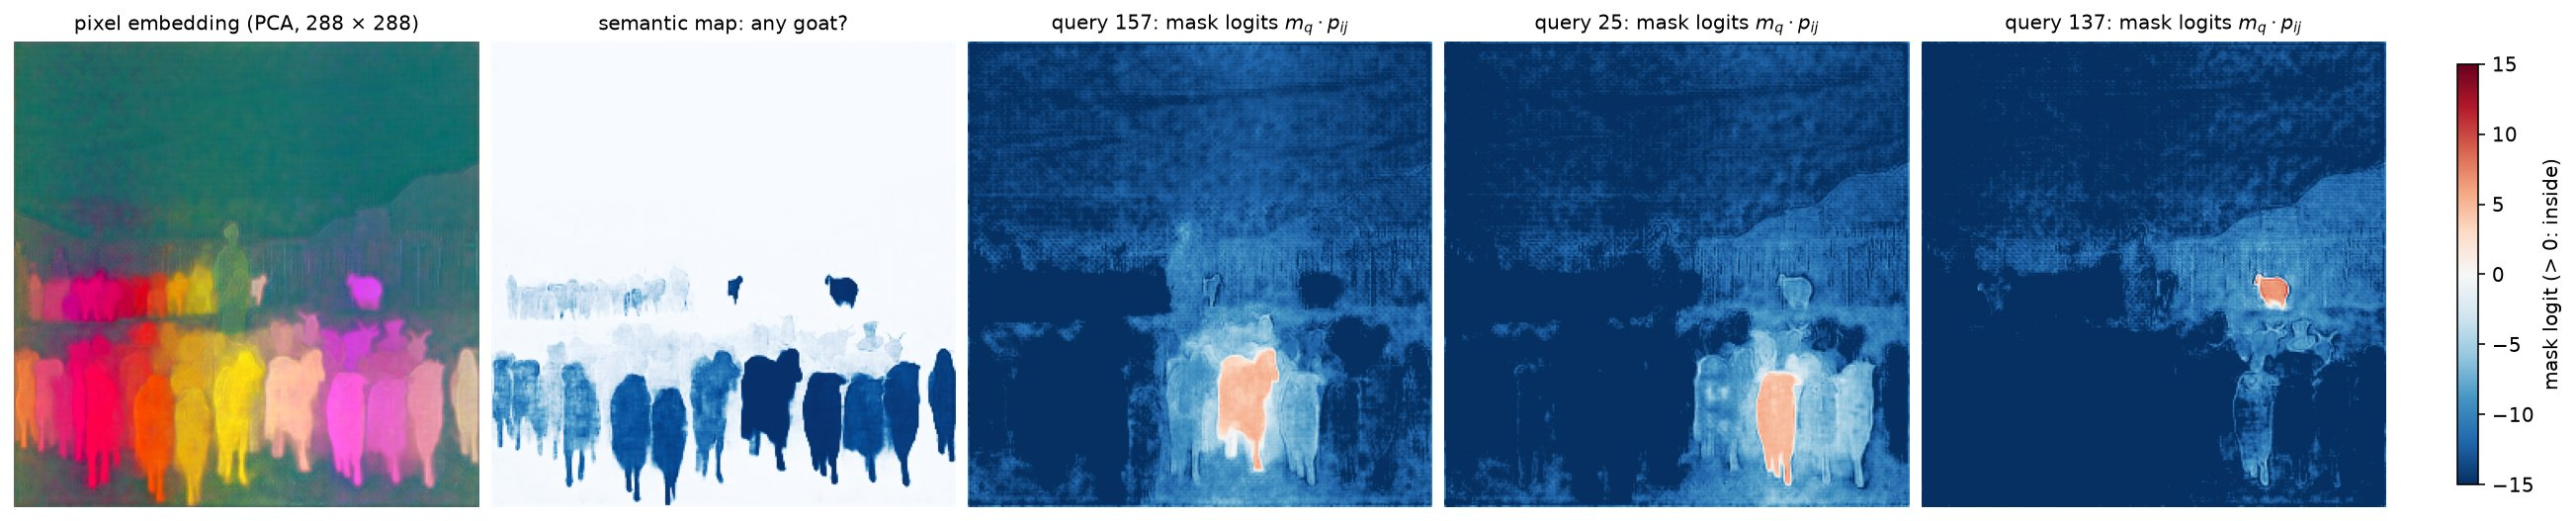

In [19]:
best = ((outputs.pred_logits.sigmoid() * outputs.presence_logits.sigmoid())[0]).argsort(descending=True)[:3]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8), layout="constrained")
axes[0].imshow(pca_rgb(pixels))
axes[0].set_title("pixel embedding (PCA, 288 × 288)", fontsize=10)
axes[1].imshow(outputs.semantic_seg[0, 0].sigmoid().cpu(), cmap="Blues", vmin=0, vmax=1)
axes[1].set_title("semantic map: any goat?", fontsize=10)
for ax, query in zip(axes[2:], best.tolist()):
    image = ax.imshow(outputs.pred_masks[0, query].cpu(), cmap="RdBu_r", vmin=-15, vmax=15)
    ax.set_title(f"query {query}: mask logits $m_q \\cdot p_{{ij}}$", fontsize=10)
for ax in axes:
    ax.axis("off")
fig.colorbar(image, ax=axes[2:], label="mask logit (> 0: inside)", shrink=0.8)
plt.show()

Each query's logits are positive (red) on its own goat and negative (blue) elsewhere, including on the other goats:
the queries have divided the objects among themselves in the decoder's self-attention. The semantic map, a 1 × 1
convolution of the pixel embedding, marks all goat pixels at once.

## Summary

- **Image** → ViT (32 layers, windowed + global attention) → feature pyramid at 4 resolutions;
- **Prompt** → CLIP text encoder → 256-d text tokens, plus box tokens from the geometry encoder;
- **DETR encoder** mixes the prompt into the image tokens; **DETR decoder** refines 200 query vectors and their boxes,
  plus a presence token;
- **Heads**: box MLP → boxes; dot product with the prompt → scores; presence MLP → presence; dot product with the pixel
  embedding → masks.